# Partie 4 : système hybride avec rejet de l'inconnu

Le système doit répondre « inconnu » plutôt que d'inventer un diagnostic quand il voit une maladie jamais apprise, ou une image qui n'est pas une feuille de tomate.

Protocole « classe inconnue » : la maladie M (virus de la mosaïque) a été retirée de l'entraînement du classifieur (fin du notebook 02). L'auto-encodeur de la partie 3, lui, n'a jamais vu de maladie. À l'évaluation, les images de M doivent être déclarées « inconnu ».

- 4.1 Baseline : rejet par probabilité softmax maximale (MSP)
- 4.2 Rejet par auto-encodeur
- 4.3 Système hybride
- 4.4 Comparaison des trois approches
- 4.5 Évaluation sur le jeu hors-distribution

**Règle importante :** tous les seuils sont fixés sur les classes **connues** de la **validation**, pour accepter 95 % des images connues. Les images de M et le test ne servent jamais à régler quoi que ce soit.

- On ajoute le dossier du projet au chemin Python pour importer notre code (`src/`).
- `config` contient les chemins, la classe M choisie et le GPU utilisé.
- `set_seed(42)` fixe le hasard : on obtient les mêmes résultats à chaque exécution.
- La dernière ligne affiche la machine utilisée (à noter dans le rapport).

In [12]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # dossier du projet, pour pouvoir importer src/

from src import config as C
C.set_seed(42)
print(C.describe_env())

Python 3.12.10, torch 2.6.0+cu124, torchvision 0.21.0+cu124
Calcul sur : cuda
GPU : NVIDIA GeForce RTX 4080 Laptop GPU
CPU : 13th Gen Intel(R) Core(TM) i7-13650HX (20 coeurs logiques)


- On recharge le classifieur entraîné sans M (fin du notebook 02), avec sa liste de classes, sa taille d'image et sa normalisation.
- On recharge l'auto-encodeur de la partie 3 (`ae_best.pt`), entraîné seulement sur des feuilles saines, avec son k et son seuil (percentile 95 des saines de validation).

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from src import data as D
from src import viz
from src import openset as OS
from src.models import build_ae, load_classifier
from src.train import fit_recon, recon_errors
from src.metrics import predict, upsert_summary, savefig

M = C.UNKNOWN_CLASS

# classifieur sans M (notebook 02)
clf, meta = load_classifier(C.CKPT_DIR / "clf_sans_M.pt")
CONNUES = meta["classes"]
SIZE = meta["size"]
NORM = meta["norm"]

# auto-encodeur des feuilles saines (notebook 03) et son seuil
seuils_ae = C.load_json(C.RESULTS / "thresholds_ae.json")
K = seuils_ae["k"]
SEUIL_AE_SAIN = seuils_ae["threshold_p95"]
ae_sain = build_ae(K).to(C.DEVICE)
ae_sain.load_state_dict(torch.load(C.CKPT_DIR / "ae_best.pt", map_location=C.DEVICE))
ae_sain.eval()

df = D.load_splits()
print("Maladie inconnue M :", D.short(M))
print("Classes connues du classifieur :", len(CONNUES))
print("Auto-encodeur de la partie 3 : k =", K, "| seuil =", round(SEUIL_AE_SAIN, 5))

Maladie inconnue M : Mosaic_virus
Classes connues du classifieur : 9
Auto-encodeur de la partie 3 : k = 16 | seuil = 0.01405


### Pourquoi M = virus de la mosaïque

- C'est une petite classe (environ 2 % des images) : la retirer gêne peu le classifieur.
- Son aspect est particulier (marbrures, feuille déformée) : c'est un bon exemple de maladie nouvelle qui pourrait arriver dans un champ.

### Le piège : l'auto-encodeur de la partie 3 détecte « malade », pas « inconnu »

Il n'a vu que des feuilles saines. Utilisé tel quel, il va aussi rejeter les 8 maladies **connues**, que le classifieur sait pourtant reconnaître. La partie 3 l'a d'ailleurs montré : il sépare mal saines et malades (AUROC autour de 0,63).

On compare donc deux auto-encodeurs :

1. l'**AE sain** de la partie 3, utilisé tel quel avec son seuil ;
2. un **AE connus** : même architecture et même k, mais entraîné sur toutes les classes connues (sans M). Lui apprend à quoi ressemble « ce que le système connaît », et c'est bien ce qu'on veut détecter.

- On entraîne le nouvel auto-encodeur sur les images d'entraînement des 9 classes connues, en 64×64, pixels entre 0 et 1, avec la même fonction `build_ae` et le même k que la partie 3.
- Perte : MSE, Adam avec un LR de 0,001, 30 époques. On garde les poids de l'époque où la perte de validation est la plus basse.
- Les poids sont enregistrés dans `results/ckpt/ae_connus.pt` (la démo les utilise).

In [14]:
donnees_train = D.subset(df, split="train", classes=CONNUES)
donnees_val = D.subset(df, split="val", classes=CONNUES)
ds_train = D.LeafDataset(donnees_train, 64, D.get_transform("ae", True), D.CLASSES)
ds_val = D.LeafDataset(donnees_val, 64, D.get_transform("ae", False), D.CLASSES)
loaders_connus = {"train": D.make_loader(ds_train, 64, shuffle=True),"val": D.make_loader(ds_val, 64)}

C.set_seed(42)
ae_connus = build_ae(K).to(C.DEVICE)
optimizer = torch.optim.Adam(ae_connus.parameters(), lr=1e-3)
fit_recon(ae_connus, loaders_connus, C.ep(30), optimizer, "ae_connus", {"type": "ae", "k": K, "size": 64})

meilleur = torch.load(C.CKPT_DIR / "ae_connus" / "best.pt", map_location=C.DEVICE, weights_only=False)
ae_connus.load_state_dict(meilleur["model"])
ae_connus.eval()
torch.save(ae_connus.state_dict(), C.CKPT_DIR / "ae_connus.pt")
print("AE connus enregistré : results/ckpt/ae_connus.pt")

Reprise depuis l'époque 30
AE connus enregistré : results/ckpt/ae_connus.pt


### Calcul des scores pour toutes les images

- On réunit dans un seul tableau les images de validation et de test (M comprise, marquée « non connue ») et toutes les images hors-distribution.
- Le classifieur donne pour chaque image la classe prédite et la **MSP** (la plus grande probabilité du softmax).
- Les deux auto-encodeurs donnent l'erreur de reconstruction de chaque image : moyenne de (x − x̂)² sur les pixels, comme dans la partie 3.
- Tout est enregistré dans `results/scores.csv`.

In [15]:
evaluation = D.subset(df, split=["val", "test"])
evaluation = evaluation[["path", "class", "split"]].rename(columns={"class": "label"})
evaluation["is_known"] = evaluation["label"].isin(CONNUES)
evaluation["ood_split"] = ""
evaluation["category"] = ""

ood = pd.read_csv(C.OOD_CSV)
ood_eval = pd.DataFrame()
ood_eval["path"] = ood["path"]
ood_eval["label"] = "OOD_" + ood["source"]
ood_eval["split"] = "ood"
ood_eval["is_known"] = False
ood_eval["ood_split"] = ood["ood_split"]
ood_eval["category"] = ood["category"]

tout = pd.concat([evaluation, ood_eval], ignore_index=True)

# classifieur classe prédite et MSP
pour_clf = tout.copy()
pour_clf["class"] = tout["label"]
ds_clf = D.LeafDataset(pour_clf, SIZE, D.get_transform("clf", False, NORM), CONNUES)
_, pred, proba = predict(clf, D.make_loader(ds_clf, 64))
noms_predits = []
for i in pred:
    noms_predits.append(CONNUES[i])
tout["pred"] = noms_predits
tout["msp"] = proba.max(axis=1)

# auto-encodeurs erreur de reconstruction
loader_ae = D.make_loader(D.LeafDataset(tout, 64, D.get_transform("ae", False)), 64)
tout["err_ae_sain"] = recon_errors(ae_sain, loader_ae)["err"]
tout["err_ae_connus"] = recon_errors(ae_connus, loader_ae)["err"]

tout.to_csv(C.SCORES_CSV, index=False)
print("Scores enregistrés dans results/scores.csv :", len(tout), "images")

Scores enregistrés dans results/scores.csv : 6129 images


## 4.1, 4.2 et 4.3 Les systèmes de rejet

Chaque système donne un **score de rejet** : plus il est grand, plus l'image est suspecte. On rejette si le score dépasse un seuil τ.

| Système | Score de rejet |
|---|---|
| MSP (4.1) | 1 − MSP |
| AE sain, seuil de la partie 3 (4.2, le piège) | erreur de l'AE sain |
| AE connus (4.2) | erreur de l'AE connus |
| Hybride, règle OU (4.3) | rejet si MSP trop basse **ou** erreur de l'AE connus trop haute |
| Hybride, score combiné (4.3) | α × z(1 − MSP) + (1 − α) × z(erreur AE connus) |

**Pourquoi la règle OU.** Les deux signaux ne voient pas la même chose. Le softmax n'a pas de case « autre » : il peut être très sûr de lui sur une image qu'il n'a jamais vue, mais l'auto-encodeur, lui, la reconstruit mal. À l'inverse, l'auto-encodeur peut bien reconstruire une maladie qui ressemble aux connues, alors que le classifieur hésite. Avec le OU, chaque signal rattrape les oublis de l'autre. C'est aussi la règle la plus facile à expliquer à un agent agricole.

On règle les deux seuils ensemble pour que le système accepte encore 95 % des connus. Si on prenait deux seuils à 95 % chacun, on rejetterait environ 10 % des connus.

**Score combiné.** La MSP et l'erreur de reconstruction n'ont pas la même échelle. On les ramène d'abord à la même échelle avec un z-score (on retire la moyenne et on divise par l'écart-type, calculés sur les connus de validation). Le poids α est choisi pour séparer au mieux les connus de validation et les **autres espèces** de la partie `calib` du jeu hors-distribution, qui ne servent pas au test.

- `val_connus` : images connues de la validation, seule base pour régler les seuils. `calib` : autres espèces réservées au choix de α.
- `ECDF` transforme un score en rang entre 0 et 1, par rapport aux connus de validation. Avec les rangs, la règle OU devient : rejet si le plus grand des deux rangs est trop haut.
- `ZScore` ramène un score à une moyenne de 0 et un écart-type de 1.
- `choose_alpha` essaie α de 0 à 1 (pas de 0,05) et garde celui qui sépare le mieux connus et autres espèces (meilleure AUROC).
- Chaque seuil est fixé pour accepter 95 % des connus de validation, sauf l'AE sain, qui garde son seuil de la partie 3. La dernière colonne le vérifie.

In [16]:
scores_df = pd.read_csv(C.SCORES_CSV, keep_default_na=False)
val_connus = scores_df[(scores_df["split"] == "val") & scores_df["is_known"]]
calib = scores_df[(scores_df["split"] == "ood") & (scores_df["ood_split"] == "calib")]

rang_msp = OS.ECDF(1 - val_connus["msp"])
rang_ae = OS.ECDF(val_connus["err_ae_connus"])
z_msp = OS.ZScore(1 - val_connus["msp"])
z_ae = OS.ZScore(val_connus["err_ae_connus"])

alpha, courbe_alpha = OS.choose_alpha(z_msp(1 - val_connus["msp"]), z_ae(val_connus["err_ae_connus"]),
                                      z_msp(1 - calib["msp"]), z_ae(calib["err_ae_connus"]))
print("alpha choisi :", alpha)


def scores_rejet(d):
    """Score de rejet des 5 systèmes pour un groupe d'images d."""
    s = {}
    s["MSP"] = 1 - d["msp"].values
    s["AE sain (seuil partie 3)"] = d["err_ae_sain"].values
    s["AE connus"] = d["err_ae_connus"].values
    s["Hybride OU"] = np.maximum(rang_msp(1 - d["msp"]), rang_ae(d["err_ae_connus"]))
    s["Hybride score combiné"] = alpha * z_msp(1 - d["msp"]) + (1 - alpha) * z_ae(d["err_ae_connus"])
    return s


scores_val = scores_rejet(val_connus)
TAU = {}
for nom in scores_val:
    TAU[nom] = np.quantile(scores_val[nom], 0.95)
TAU["AE sain (seuil partie 3)"] = SEUIL_AE_SAIN

for nom in TAU:
    acceptes = (scores_val[nom] <= TAU[nom]).mean()
    print(f"{nom:28s} seuil = {TAU[nom]:.4f}   connus de validation acceptés : {acceptes:.3f}")

alpha choisi : 1.0
MSP                          seuil = 0.0157   connus de validation acceptés : 0.950
AE sain (seuil partie 3)     seuil = 0.0140   connus de validation acceptés : 0.808
AE connus                    seuil = 0.0144   connus de validation acceptés : 0.950
Hybride OU                   seuil = 0.9748   connus de validation acceptés : 0.950
Hybride score combiné        seuil = 0.1805   connus de validation acceptés : 0.950


## 4.4 Comparaison sur le test

- On sépare le test en images connues et images de M.
- `bonne_classe` dit, pour chaque image connue, si le classifieur a trouvé la bonne maladie.
- Pour chaque système, les 4 mesures demandées : AUROC connu contre M (qualité de séparation, sans seuil), part de M rejetée, part des connus rejetés à tort, accuracy sur les connus acceptés.
- Les résultats vont aussi dans `summary.csv` pour le tableau récapitulatif.

In [17]:
test_connus = scores_df[(scores_df["split"] == "test") & scores_df["is_known"]]
test_M = scores_df[(scores_df["split"] == "test") & (scores_df["label"] == M)]
s_connus = scores_rejet(test_connus)
s_M = scores_rejet(test_M)
bonne_classe = (test_connus["pred"] == test_connus["label"]).values
print(f"Test : {len(test_connus)} images connues, {len(test_M)} images de M")
print(f"Accuracy du classifieur sur les connues, sans rejet : {bonne_classe.mean():.4f}")

lignes = {}
for nom in TAU:
    r = OS.system_metrics(s_connus[nom], s_M[nom], TAU[nom], bonne_classe)
    lignes[nom] = {"AUROC connu / M": r["auroc_known_vs_M"],
                   "rejet de M": r["rejet_M"],
                   "rejet à tort des connus": r["rejet_a_tort_connus"],
                   "accuracy sur les connus acceptés": r["acc_connus_acceptes"]}
    upsert_summary({"experiment": f"P4_{nom}", "partie": 4, "modele": nom,
                    "hyperparametres": f"seuil {TAU[nom]:.4g}",
                    "test_auroc": round(r["auroc_known_vs_M"], 4),
                    "test_rejet_M": round(r["rejet_M"], 4),
                    "test_rejet_a_tort": round(r["rejet_a_tort_connus"], 4),
                    "test_acc_acceptes": round(r["acc_connus_acceptes"], 4)})

pd.DataFrame(lignes).T.round(4)

Test : 2670 images connues, 55 images de M
Accuracy du classifieur sur les connues, sans rejet : 0.9933


,AUROC connu / M,rejet de M,rejet à tort des connus,accuracy sur les connus acceptés
MSP,0.9519,0.7455,0.0536,1.0000
AE sain (seuil partie 3),0.3433,0.0182,0.1944,0.9940
AE connus,0.4245,0.0000,0.0551,0.9937
Hybride OU,0.9140,0.6000,0.0494,0.9988
Hybride score combiné,0.9519,0.7455,0.0536,1.0000


- Pour tracer la courbe, on accepte les images en commençant par les moins suspectes. En x : la part des images acceptées ; en y : l'accuracy sur ces images.
- Une image de M acceptée compte comme une erreur, car le système donne alors un faux diagnostic.
- Le meilleur système est celui dont la courbe reste la plus haute.

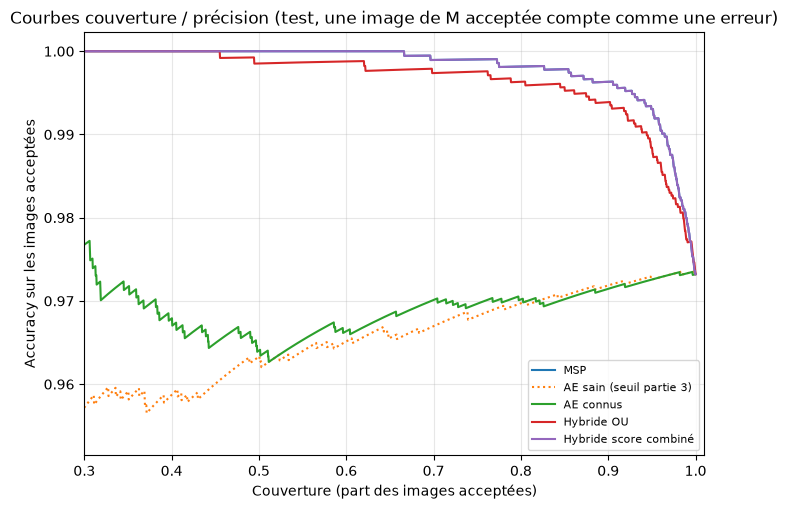

In [18]:
plt.figure(figsize=(8, 5.5))
for nom in TAU:
    tous_scores = np.concatenate([s_connus[nom], s_M[nom]])
    correct = np.concatenate([bonne_classe, np.zeros(len(test_M), dtype=bool)])
    couverture, precision = OS.coverage_accuracy_curve(tous_scores, correct)
    if nom == "AE sain (seuil partie 3)":
        plt.plot(couverture, precision, linestyle=":", label=nom)
    else:
        plt.plot(couverture, precision, label=nom)
plt.xlabel("Couverture (part des images acceptées)")
plt.ylabel("Accuracy sur les images acceptées")
plt.title("Courbes couverture / précision (test, une image de M acceptée compte comme une erreur)")
plt.xlim(0.3, 1.01)
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
savefig("04_couverture_precision.png")
plt.show()

- Histogrammes du score de rejet pour les images connues, les images de M et les images hors-distribution, avec le seuil en pointillés.
- Pour la MSP, on s'attend à voir des images de M et hors-distribution avec un score proche de 0 : le softmax est sûr de lui alors qu'il se trompe.

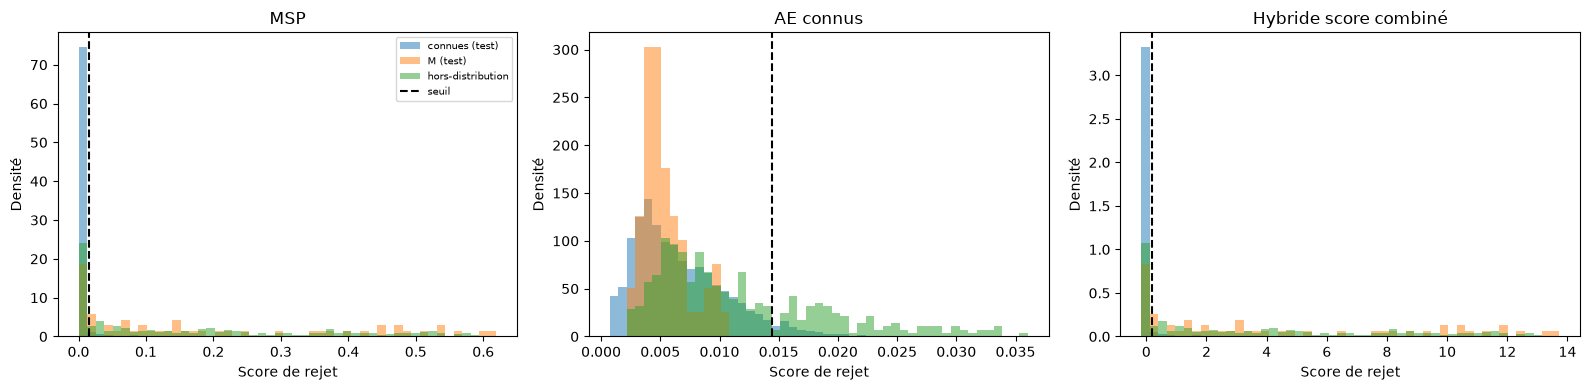

In [19]:
ood_e = scores_df[(scores_df["split"] == "ood") & (scores_df["ood_split"] == "eval")]
s_ood = scores_rejet(ood_e)

noms = ["MSP", "AE connus", "Hybride score combiné"]
plt.figure(figsize=(16, 4))
for i in range(3):
    nom = noms[i]
    plt.subplot(1, 3, i + 1)
    valeurs = np.concatenate([s_connus[nom], s_M[nom], s_ood[nom]])
    bins = np.linspace(valeurs.min(), np.quantile(valeurs, 0.995), 50)
    plt.hist(s_connus[nom], bins, alpha=0.5, density=True, label="connues (test)")
    plt.hist(s_M[nom], bins, alpha=0.5, density=True, label="M (test)")
    plt.hist(s_ood[nom], bins, alpha=0.5, density=True, label="hors-distribution")
    plt.axvline(TAU[nom], color="k", linestyle="--", label="seuil")
    plt.title(nom)
    plt.xlabel("Score de rejet")
    plt.ylabel("Densité")
    if i == 0:
        plt.legend(fontsize=7)
plt.tight_layout()
savefig("04_histogrammes.png")
plt.show()

### Ce qu'on observe

- **MSP.** C'est le meilleur sur la maladie inconnue : il rejette 74,5 % des images de M, n'en rejette à tort que 5,4 % des connues, et il ne fait plus aucune erreur sur les connues acceptées (accuracy 1,000). L'AUROC connu / M est de 0,952. Mais une image sur quatre de M passe quand même, avec une MSP souvent élevée : la MSP moyenne sur M est de 0,81. Le softmax n'a pas de case « autre », il range toujours l'image dans une des 9 classes.
- **AE sain (le piège).** Comme prévu, il rejette à tort 19,4 % des images connues, presque 4 fois plus que les autres systèmes, parce que les maladies connues sont pour lui des anomalies. Et il ne rejette que 1,8 % de M. Son AUROC (0,34) est même sous 0,5 : M est en moyenne **mieux** reconstruite que les maladies connues. Cela confirme la partie 3, où Mosaic_virus n'était détectée que dans 2 % des cas.
- **AE connus.** Il ne rejette aucune image de M (AUROC 0,42). L'histogramme du milieu montre pourquoi : les erreurs de M sont tassées entre 0,004 et 0,006, en plein dans celles des connues. Avec k = 16, l'auto-encodeur ne garde que la couleur et la forme générale de la feuille. Une feuille de mosaïque photographiée sur le même fond, avec la même lumière, lui paraît normale : les marbrures sont des détails trop fins pour peser dans l'erreur.
- **Hybride OU.** Il rejette 60 % de M, moins que la MSP seule. C'est le prix du réglage commun : pour garder 95 % des connus avec deux conditions, le seuil sur la MSP descend à 0,930 au lieu d'environ 0,984. L'auto-encodeur ne rattrape presque aucune image de M, donc la règle OU perd un peu sur M. En échange, il a le plus faible rejet à tort (4,9 %).
- **Hybride score combiné.** Le α choisi sur les autres espèces vaut 1 : le score combiné est exactement la MSP. Sa courbe couverture / précision cache donc celle de la MSP (la ligne violette est posée sur la bleue). Sur les autres espèces photographiées au laboratoire, l'auto-encodeur n'apportait rien de plus que la MSP.
- **Courbes couverture / précision.** La MSP et le score combiné restent les plus hauts : ils gardent 100 % d'accuracy jusqu'à environ 67 % de couverture. La règle OU est juste en dessous. Les deux auto-encodeurs sont sous 0,975 sur toute la courbe : ils acceptent d'abord les images les mieux reconstruites, dont les images de M, ce qui fait entrer des erreurs dès le début.

**Bilan sur M.** Pour une maladie nouvelle photographiée dans les mêmes conditions que l'entraînement, c'est le classifieur qui donne le meilleur signal. L'auto-encodeur, réglé sur l'apparence globale de l'image, ne voit pas la différence.

## 4.5 Évaluation sur le jeu hors-distribution

- Pour chaque système et chaque catégorie d'images hors-distribution : la part d'images rejetées. Un bon système rejette presque tout ici.
- On affiche aussi la MSP moyenne : si les images hors-distribution ont une MSP élevée, le softmax seul est dangereux.

In [20]:
categories = sorted(ood_e["category"].unique())
taux = {}
for nom in TAU:
    rejete = s_ood[nom] > TAU[nom]
    ligne = {}
    for cat in categories:
        dans_cat = (ood_e["category"] == cat).values
        ligne[cat] = rejete[dans_cat].mean()
    ligne["TOTAL hors-distribution"] = rejete.mean()
    taux[nom] = ligne
tableau_ood = pd.DataFrame(taux).T

print("MSP moyenne : connues", round(test_connus["msp"].mean(), 3),
      "| M", round(test_M["msp"].mean(), 3),
      "| hors-distribution", round(ood_e["msp"].mean(), 3))
print("Images hors-distribution avec une MSP > 0,9 :", round((ood_e["msp"] > 0.9).mean(), 3))
print("Taux de rejet par catégorie :")
tableau_ood.round(3)

MSP moyenne : connues 0.992 | M 0.807 | hors-distribution 0.813
Images hors-distribution avec une MSP > 0,9 : 0.486
Taux de rejet par catégorie :


,Blueberry,Cherry_(including_sour),Corn_(maize),"Pepper,_bell",Potato,Soybean,Strawberry,mains,sol_objets,tomate_terrain_plantdoc,TOTAL hors-distribution
MSP,1.000,0.690,0.726,0.762,0.571,1.000,0.738,0.5,0.75,0.516,0.695
AE sain (seuil partie 3),0.810,0.214,0.500,0.690,0.349,0.619,0.381,1.0,0.75,0.968,0.572
AE connus,0.000,0.000,0.393,0.238,0.079,0.000,0.167,1.0,0.65,0.855,0.322
Hybride OU,0.952,0.548,0.655,0.738,0.460,0.762,0.667,1.0,0.85,0.855,0.693
Hybride score combiné,1.000,0.690,0.726,0.762,0.571,1.000,0.738,0.5,0.75,0.516,0.695


- 4 images par catégorie hors-distribution, avec la décision du système hybride OU : en vert l'image est rejetée, en rouge le système donne une maladie (avec sa MSP).
- Cas à regarder de près : les feuilles de tomate de terrain (PlantDoc). Ce sont de vraies feuilles de tomate, souvent malades, mais photographiées au champ. Si elles sont rejetées, c'est encore le biais de fond de PlantVillage (partie 6).

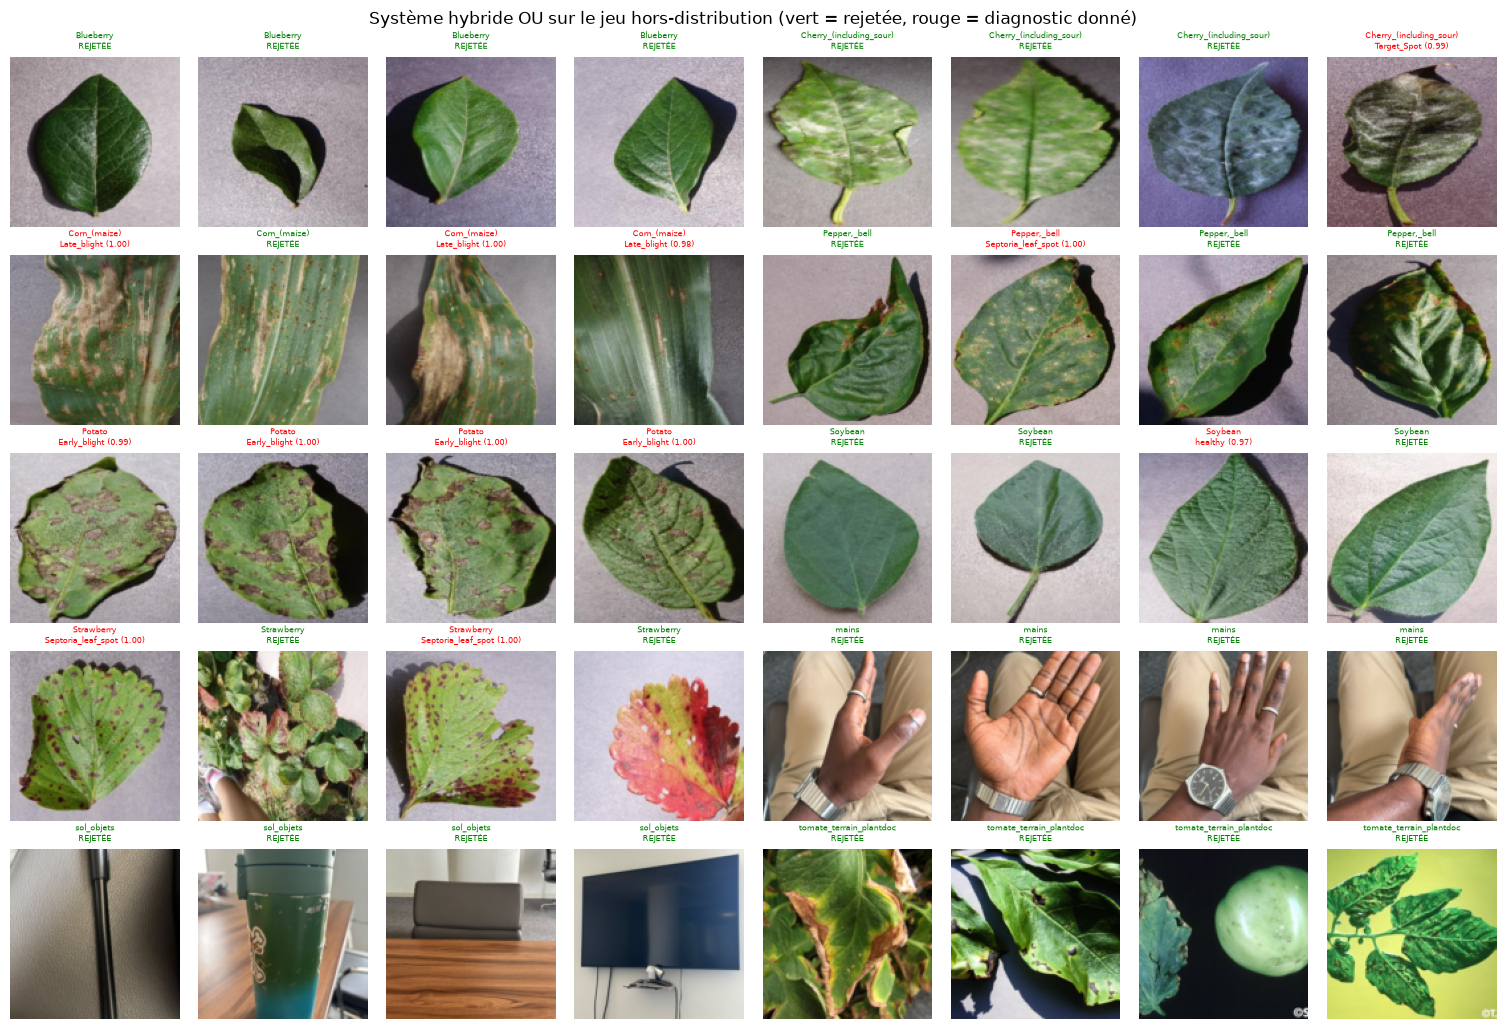

In [21]:
exemples = ood_e.groupby("category").head(4)
s_ex = scores_rejet(exemples)["Hybride OU"]

images = []
titres = []
couleurs = []
for i in range(len(exemples)):
    ligne = exemples.iloc[i]
    images.append(D.read_rgb(C.resolve(ligne["path"]), 128))
    if s_ex[i] > TAU["Hybride OU"]:
        titres.append(ligne["category"] + "\nREJETÉE")
        couleurs.append("green")
    else:
        titres.append(f"{ligne['category']}\n{D.short(ligne['pred'])} ({ligne['msp']:.2f})")
        couleurs.append("red")

viz.image_grid(images, titres, ncols=8, size=1.9, title_fs=6, colors=couleurs,
               path=C.FIG_DIR / "04_ood_exemples.png",
               suptitle="Système hybride OU sur le jeu hors-distribution (vert = rejetée, rouge = diagnostic donné)")

- On traduit la règle OU en deux seuils simples : rejet si la MSP est sous `msp_min` **ou** si l'erreur de l'auto-encodeur dépasse `err_max`.
- On enregistre tout dans `results/hybrid_config.json`, que la démo utilise.

In [22]:
q = TAU["Hybride OU"]
msp_min = float(1 - np.quantile(1 - val_connus["msp"], q))
err_max = float(np.quantile(val_connus["err_ae_connus"], q))

config_demo = {"classes": CONNUES, "clf_ckpt": "clf_sans_M.pt", "ae_ckpt": "ae_connus.pt", "ae_k": K,
               "clf_size": SIZE, "ae_size": 64, "norm": NORM, "default_rule": "or",
               "or": {"msp_min": msp_min, "err_max": err_max},
               "score": {"alpha": float(alpha), "z_msp": [z_msp.m, z_msp.s], "z_err": [z_ae.m, z_ae.s],
                         "tau": float(TAU["Hybride score combiné"])}}
C.save_json(config_demo, C.RESULTS / "hybrid_config.json")
print("Règle OU : rejet si MSP <", round(msp_min, 4), "ou erreur AE >", round(err_max, 5))

Règle OU : rejet si MSP < 0.9301 ou erreur AE > 0.01696


## Conclusion de la partie 4

**Sur le jeu hors-distribution, aucun système n'est fiable seul.**

- **Nos photos de mains montrent le danger du softmax.** Le classifieur classe les 10 mains en « Early_blight », et 5 fois sur 10 avec une MSP au-dessus de 0,99 : la couleur brune de la peau et ses plis ressemblent pour lui aux taches de la maladie. La MSP seule n'en rejette que la moitié. L'auto-encodeur, lui, les reconnaît toutes comme anormales : erreur entre 0,023 et 0,038, bien au-dessus du seuil de 0,017. La règle OU rejette les 10 mains.
- **Sur nos 20 photos d'objets**, la MSP en rejette 75 % et la règle OU 85 %. Les 3 objets que la règle OU accepte sont parlants : un tapis gris uni (classé « healthy » avec une MSP de 0,99 et l'erreur de reconstruction la plus basse de toutes nos photos, 0,003), une chaussure noire posée sur ce tapis, et un ordinateur portable. Un fond gris uni, c'est exactement le fond des photos de PlantVillage : l'auto-encodeur le reconstruit parfaitement, et le classifieur y voit une feuille. On retrouve le biais de fond de la partie 6.
- **Sur les autres espèces de PlantVillage**, près de la moitié des images hors-distribution (48,6 %) reçoivent une MSP supérieure à 0,9. Des feuilles de pomme de terre sont classées « Early_blight » et du maïs « Late_blight », avec une MSP de 1,00. Ce n'est pas un hasard : l'alternariose et le mildiou de la pomme de terre sont causés par les mêmes champignons que chez la tomate. Le classifieur reconnaît la maladie, mais il ne sait pas dire que ce n'est pas une tomate. Ici l'auto-encodeur aide peu : les photos sont prises sur le même fond, avec la même lumière (myrtille et soja : 0 % de rejet par l'AE connus).
- **Sur les feuilles de tomate prises au champ (PlantDoc)**, la MSP n'en rejette que 51,6 % et donne un diagnostic pour l'autre moitié, alors que la partie 6 a montré que le classifieur dépend beaucoup du fond. La règle OU en rejette 85,5 %.

Les deux signaux se complètent : le classifieur repère ce qui ne ressemble à aucune maladie connue, l'auto-encodeur repère ce qui ne ressemble pas aux photos d'entraînement (mains, objets, fond naturel).

**Quel système est le plus robuste ?** Sur la maladie inconnue M, la MSP (74,5 % de M rejetée contre 60 % pour la règle OU). Mais un vrai système recevra des photos prises au téléphone, avec des doigts, le sol et d'autres objets dans le cadre. Sur ces images, la MSP peut donner un diagnostic avec une confiance de 99 % sur une main. **On garde donc la règle OU pour la démo** :
- elle rejette 100 % des mains, 85 % des objets et 85,5 % des feuilles de terrain ;
- elle a le plus faible rejet à tort des connus (4,9 %) ;
- chaque seuil se comprend facilement : « la machine n'est pas sûre » ou « la photo ne ressemble pas à ce qu'elle connaît ».

**Limites.**
- M n'a que 55 images de test : un écart de 5 points correspond à 3 images. Nos photos personnelles sont aussi peu nombreuses (30).
- Un fond gris uni trompe les deux signaux à la fois : il faudrait des données d'entraînement avec d'autres fonds.
- Le α du score combiné est choisi sur d'autres espèces photographiées au laboratoire. Elles ressemblent trop aux images d'entraînement pour que l'auto-encodeur y serve, d'où α = 1. Avec nos photos ou des photos de terrain comme jeu de calibration, le choix serait sans doute différent, mais nous les gardons pour l'évaluation.